## Step 5: What do those genes do together?

Step 4 gave us thousands of genes, which is too many to read one by one. A **pathway** is a group of genes that work together on one job, like dividing the cell, building blood vessels, or sending signals between brain cells. This step asks which jobs show up more often than chance in each comparison.

I used two methods, and they answer slightly different questions.

- **Method 1, ranking the whole gene list.** I lined up all genes from the most active in the aggressive group to the most active in the other group, and then ask whether the genes in a pathway bunch up at one end. This is called GSEA. It uses every gene, so it does not depend on a cutoff. A positive score (NES) means the pathway is higher in the more aggressive group. I used the 50 Hallmark pathways, which are broad and easy to read.
- **Method 2, testing the gene lists.** I took the genes that came out different in step 4 and ask which pathways have more of them than chance would give. This is called over-representation. I use the Gene Ontology biological processes, which are more detailed, so this is where brain-cell genes will show up. The test compares against all 20,511 genes I measured, not the whole genome.

I run method 2 on the genes shared by comparisons A and B, which are the most trustworthy IDH genes, and on comparison C, which is the progression question.

Before either method, I drop the pseudogene and LOC style genes and the genes flagged in comparison C in step 4. Pseudogenes are not in any pathway list anyway, so this just keeps the ranking clean.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gseapy as gp

plt.rcParams["font.size"] = 20

purple = "#5B3A8C"
dark_blue = "#1F3A6B"
light_purple = "#A794C9"

Path("csv").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
print("Done")

Done


In [2]:
#Load the step 4 results and clean them --> A gene is left out if its name looks like a LOC entry or pseudogene, and in comparison C also if it goes from clearly active in lower grade to nearly off in glioblastoma.
results = {key: pd.read_csv("csv/de_" + key + ".csv") for key in ["A", "B", "C"]}

name_pattern = r"^LOC\d+|P\d+$"
for key, table in results.items():
    table["usable"] = ~table["gene"].str.contains(name_pattern, regex=True)
results["C"]["usable"] = results["C"]["usable"] & ~((results["C"]["mean_group"] <= 3) & (results["C"]["mean_baseline"] >= 6))

all_genes = results["A"]["gene"].tolist()
for key, table in results.items():
    print("Comparison " + key + ": " + str(int(table["usable"].sum())) + " of " + str(len(table)) + " genes kept")

Comparison A: 18949 of 20511 genes kept
Comparison B: 18949 of 20511 genes kept
Comparison C: 18947 of 20511 genes kept


#### Download the pathway lists
`MSigDB_Hallmark_2020` is the 50 Hallmark pathways. `GO_Biological_Process_2023` is the detailed list of biological processes. The last lines check how many of the genes in the pathway lists are also in our data. If that share is low, gene names would not be matching up.

In [3]:
hallmark = gp.get_library("MSigDB_Hallmark_2020")
go_bp = gp.get_library("GO_Biological_Process_2023")
print("Hallmark pathways:", len(hallmark))
print("Gene Ontology processes:", len(go_bp))

measured = set(all_genes)
for name, library in [("Hallmark", hallmark), ("Gene Ontology", go_bp)]:
    in_lists = set(g for genes in library.values() for g in genes)
    print(name + ": share of pathway genes found in our data:", round(len(in_lists & measured) / len(in_lists) * 100), "%")

Hallmark pathways: 50
Gene Ontology processes: 5406
Hallmark: share of pathway genes found in our data: 96 %
Gene Ontology: share of pathway genes found in our data: 88 %


### Method 1, ranking the whole gene list
Each gene gets a score that is the direction of the change times the strength of the evidence (the minus log10 of the p-value). Genes at the top are the most active in the aggressive group and genes at the bottom are the most active in the other group. This takes a minute or two per comparison, because it shuffles the labels 1,000 times to see what chance looks like.

In [4]:
titles = {"A": "A: IDH wild-type versus IDH mutant, everyone",
          "B": "B: IDH wild-type versus IDH mutant, lower grade only",
          "C": "C: Glioblastoma versus lower grade, IDH wild-type only"}

hallmark_results = {}
for key, table in results.items():
    usable = table[table["usable"]]
    score = np.sign(usable["log2_fold_change"]) * -np.log10(np.maximum(usable["p_value"], 1e-300))
    ranked = pd.Series(score.to_numpy(), index=usable["gene"].to_numpy()).sort_values(ascending=False)

    pre = gp.prerank(rnk=ranked, gene_sets=hallmark, min_size=15, max_size=500,
                     permutation_num=1000, seed=1, threads=4, outdir=None, verbose=False)
    res = pre.res2d.copy()
    res["NES"] = res["NES"].astype(float)
    res["FDR q-val"] = res["FDR q-val"].astype(float)
    res = res.sort_values("NES", ascending=False).reset_index(drop=True)
    hallmark_results[key] = res
    res.to_csv("csv/pathways_hallmark_" + key + ".csv", index=False)

    print("Comparison " + titles[key])
    print("Pathways with an FDR below 0.05:", int((res["FDR q-val"] < 0.05).sum()), "of", len(res))
    print()

2026-10-28 20:34:20,676 [WARNING] Duplicated values found in preranked stats: 1.58% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-28 20:34:22,296 [WARNING] Duplicated values found in preranked stats: 1.72% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Comparison A: IDH wild-type versus IDH mutant, everyone
Pathways with an FDR below 0.05: 25 of 50



2026-10-28 20:34:23,973 [WARNING] Duplicated values found in preranked stats: 2.63% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Comparison B: IDH wild-type versus IDH mutant, lower grade only
Pathways with an FDR below 0.05: 24 of 50

Comparison C: Glioblastoma versus lower grade, IDH wild-type only
Pathways with an FDR below 0.05: 30 of 50



### The Hallmark pathways in each comparison
Purple bars are pathways higher in the more aggressive group (IDH wild-type, or glioblastoma). Dark blue bars are pathways higher in the other group. Only pathways with an FDR below 0.05 are shown, up to the 12 strongest.

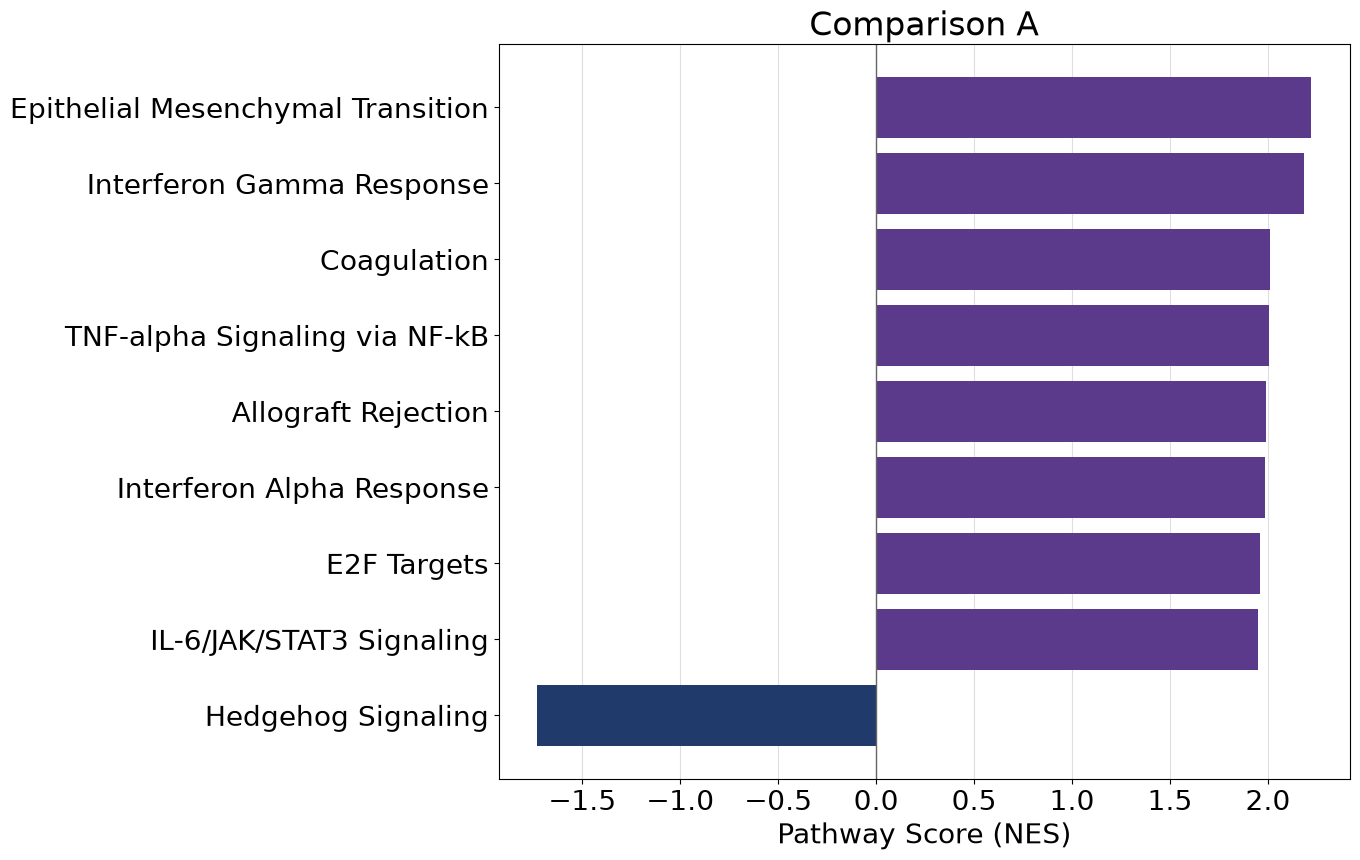

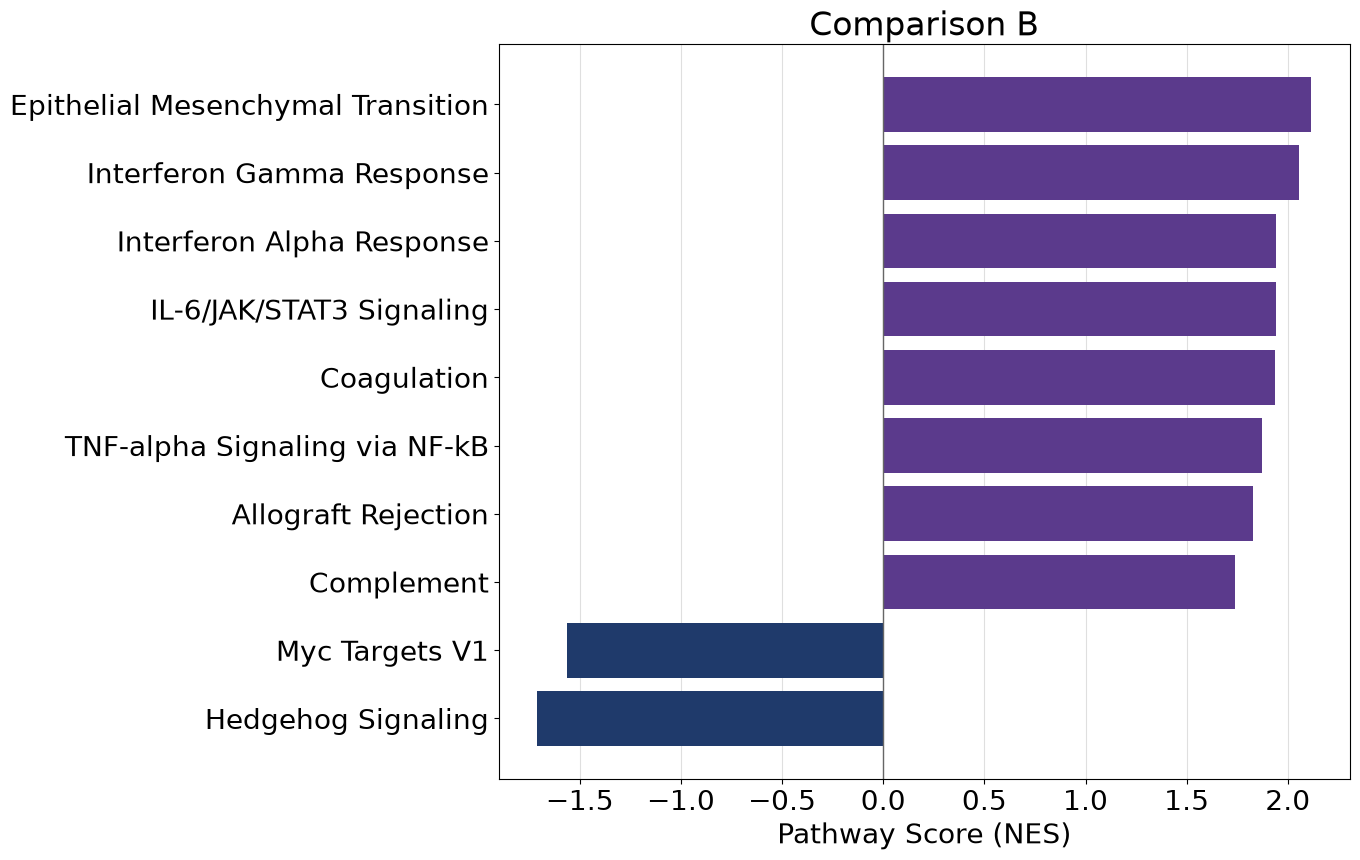

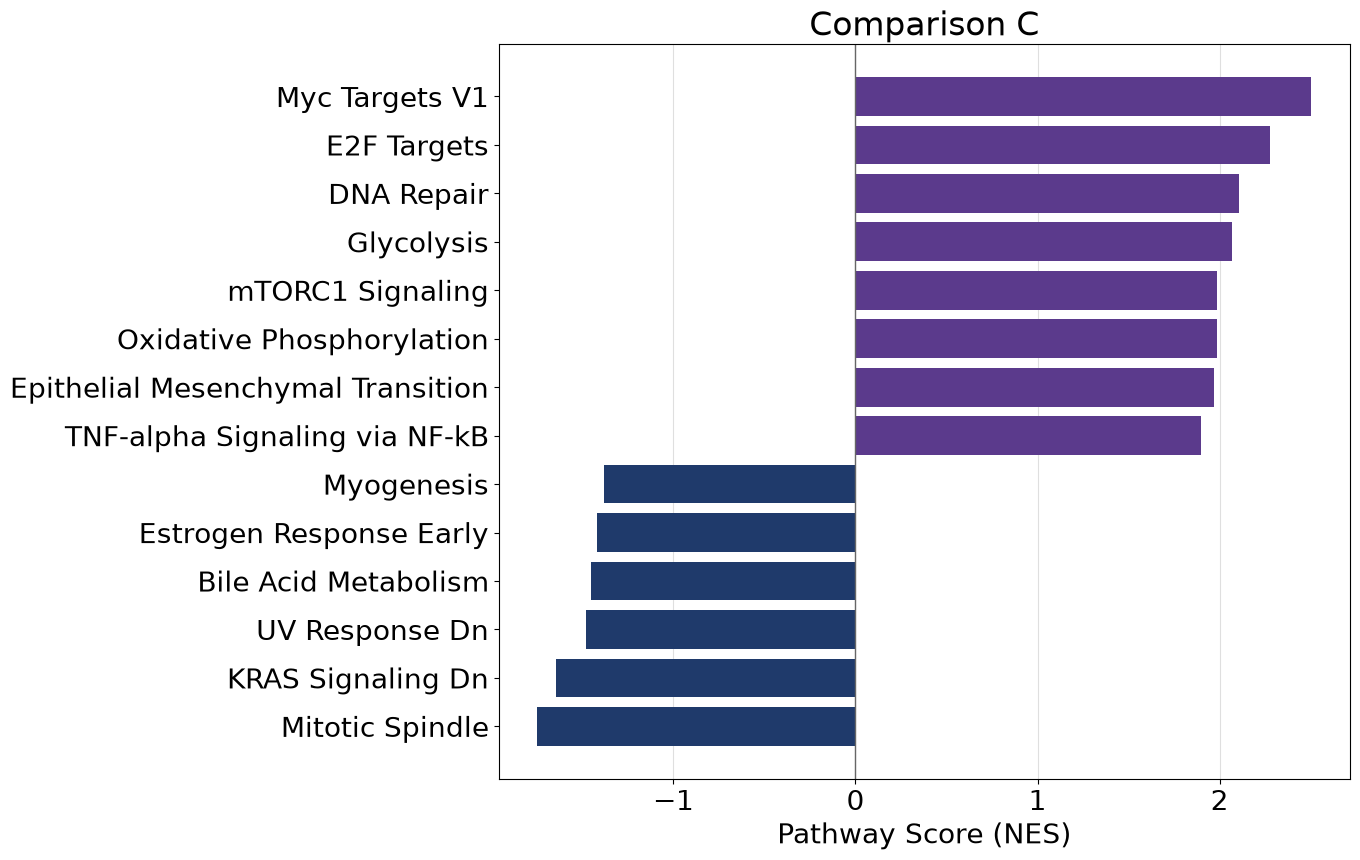

In [8]:
for key, res in hallmark_results.items():
    significant = res[res["FDR q-val"] < 0.05]
    higher = significant[significant["NES"] > 0].nlargest(8, "NES")
    lower = significant[significant["NES"] < 0].nsmallest(8, "NES")
    strongest = pd.concat([higher, lower]).sort_values("NES")

    if len(strongest) == 0:
        print("Comparison " + key + ": no pathways passed")
        continue

    fig, ax = plt.subplots(figsize=(14, 9))
    colors = [purple if value > 0 else dark_blue for value in strongest["NES"]]
    ax.barh(strongest["Term"], strongest["NES"], color=colors)
    ax.axvline(0, color="#666666", linewidth=1)
    ax.set_title("Comparison " + key)
    ax.set_xlabel("Pathway Score (NES)")
    ax.grid(True, axis="x", alpha=0.4)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig("figures/p4-hallmark-" + key + ".png", dpi=150, bbox_inches="tight")
    plt.show()

In [6]:
for key, res in hallmark_results.items():
    significant = res[res["FDR q-val"] < 0.05]
    print("Comparison " + titles[key])
    print()
    print("Higher in the more aggressive group:")
    print(significant[significant["NES"] > 0].head(8)[["Term", "NES", "FDR q-val"]].to_string(index=False))
    print()
    print("Higher in the other group:")
    print(significant[significant["NES"] < 0].sort_values("NES").head(8)[["Term", "NES", "FDR q-val"]].to_string(index=False))
    print()
    print()

Comparison A: IDH wild-type versus IDH mutant, everyone

Higher in the more aggressive group:
                             Term      NES  FDR q-val
Epithelial Mesenchymal Transition 2.221213        0.0
        Interferon Gamma Response 2.184309        0.0
                      Coagulation 2.009691        0.0
    TNF-alpha Signaling via NF-kB 2.002870        0.0
              Allograft Rejection 1.989819        0.0
        Interferon Alpha Response 1.983722        0.0
                      E2F Targets 1.958323        0.0
         IL-6/JAK/STAT3 Signaling 1.950611        0.0

Higher in the other group:
              Term       NES  FDR q-val
Hedgehog Signaling -1.729486   0.001679


Comparison B: IDH wild-type versus IDH mutant, lower grade only

Higher in the more aggressive group:
                             Term      NES  FDR q-val
Epithelial Mesenchymal Transition 2.116241   0.000000
        Interferon Gamma Response 2.056382   0.000000
        Interferon Alpha Response 1.942480   0

### Method 2, testing the gene lists
Here I take the genes that came out different in step 4 and ask which Gene Ontology processes have more of them than chance. There are four lists.

- Genes higher in IDH wild-type in both A and B
- Genes higher in IDH mutant in both A and B
- Genes higher in glioblastoma in C
- Genes higher in lower grade in C

The score to look at is the adjusted p-value, and the odds ratio says how strong the bunching is.

In [7]:
shared = pd.read_csv("csv/de_A_and_B_shared.csv")
shared = shared[~shared["gene"].str.contains(name_pattern, regex=True)]

c_table = results["C"]
c_different = c_table[c_table["different"] & c_table["usable"]]

gene_lists = {
    "Shared A and B, higher in IDH wild-type": shared.loc[shared["direction"] == "Higher in IDH wild-type", "gene"].tolist(),
    "Shared A and B, higher in IDH mutant": shared.loc[shared["direction"] == "Higher in IDH mutant", "gene"].tolist(),
    "C, higher in glioblastoma": c_different.loc[c_different["log2_fold_change"] > 0, "gene"].tolist(),
    "C, higher in lower grade": c_different.loc[c_different["log2_fold_change"] < 0, "gene"].tolist(),
}

go_results = {}
for name, genes in gene_lists.items():
    if len(genes) < 10:
        print(name + ": too few genes to test (" + str(len(genes)) + ")")
        print()
        continue
    enriched = gp.enrichr(gene_list=genes, gene_sets=go_bp, background=all_genes, outdir=None, cutoff=1.0)
    table = enriched.results.sort_values("Adjusted P-value").reset_index(drop=True)
    go_results[name] = table
    table.to_csv("csv/pathways_go_" + name.lower().replace(",", "").replace(" ", "_") + ".csv", index=False)

    print(name + " (" + str(len(genes)) + " genes)")
    print(table.head(8)[["Term", "Overlap", "Adjusted P-value"]].to_string(index=False))
    print()
    print()

Shared A and B, higher in IDH wild-type (1336 genes)
                                                                                      Term Overlap  Adjusted P-value
                                        MHC Class II Protein Complex Assembly (GO:0002399)   10/12      6.494910e-08
Immunoglobulin Production Involved In Immunoglobulin-Mediated Immune Response (GO:0002381)   11/14      6.494910e-08
                              Negative Regulation Of Viral Genome Replication (GO:0045071)   19/49      6.494910e-08
                   Peptide Antigen Assembly With MHC Class II Protein Complex (GO:0002503)   10/12      6.494910e-08
                                            Extracellular Matrix Organization (GO:0030198)  36/165      6.686143e-08
                                     Anterior/Posterior Pattern Specification (GO:0009952)   20/58      1.550874e-07
                                      Immunoglobulin Mediated Immune Response (GO:0016064)   14/28      1.863440e-07
           